# Import right dependencies

In [1]:
import numpy as np
import h5py
import cv2
import numpy
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from keras.datasets import mnist
from sklearn.metrics import classification_report, confusion_matrix

# Import dataset

In [2]:
(train_X, train_y), (test_X, test_y) = mnist.load_data()
print(train_X.shape)
print(train_y.shape)

(60000, 28, 28)
(60000,)


# One hot encode train and test labels

In [3]:
train_y_one_hot= to_categorical(train_y)
train_y_one_hot = np.einsum('vz->zv', train_y_one_hot)
test_y_one_hot= to_categorical(test_y)
test_y_one_hot = np.einsum('vz->zv', test_y_one_hot)
print(train_X.shape)
print(train_y_one_hot.shape)

(60000, 28, 28)
(10, 60000)


# Flatten and reshape train and test inputs

In [4]:
train_x_flatten = train_X.reshape(train_X.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_X.reshape(test_X.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.

print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))

train_x's shape: (784, 60000)
test_x's shape: (784, 10000)


# Define neural network architecture

In [5]:
#input dymension, hidden_layers
layers_dims = [784, 30, 20, 15, 10]

# Define activation functions

In [6]:
def relu(z):
    A = np.maximum(0,z)
    cache = z 
    return A, cache

In [7]:
def sigmoid(z):
    s = 1 / (1 + np.exp(-z))
    cache = z
    return s, cache

In [8]:
def softmax(z):
    cache = z
    z_norm = z - np.max(z, axis=0, keepdims=True)   # max of each column
    exp = np.exp(z_norm)
    exp = exp / np.sum(exp, axis=0, keepdims=True)
    return exp, cache

# Define forward propagation functions

In [9]:
def initialize_parameters_deep(layer_dims):
    np.random.seed(1)
    parameters = {}
    L = len(layer_dims)            # number of layers in the network

    for l in range(1, L):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) / np.sqrt(layer_dims[l-1])
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))

    return parameters

In [10]:
def linear_forward(A, W, b):
    Z = np.dot(W, A) + b
    cache = (A, W, b)
    return Z, cache

In [11]:
def linear_activation_forward(A_prev, W, b, activation):
    if activation == "sigmoid":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = sigmoid(Z)
    
    elif activation == "softmax":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = softmax(Z)
    
    elif activation == "relu":
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = relu(Z)
    cache = (linear_cache, activation_cache)

    return A, cache

# Define model forward function

In [12]:
def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2            

    for l in range(1, L):
        A_prev = A 
        A, cache = linear_activation_forward(A_prev, parameters['W' + str(l)], parameters['b' + str(l)], "relu")
        caches.append(cache)
    
    AL, cache = linear_activation_forward(A, parameters['W' + str(L)], parameters['b' + str(L)], "softmax")
    caches.append(cache)
    
    return AL, caches

# Define cost functions

In [13]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = -np.mean(Y * np.log(AL))
    cost = np.squeeze(cost)
    return cost

# Define activation function derivatives with respect to loss

In [14]:
def sigmoid_backward(dA, cache):
    Z = cache 
    s = 1 / (1 + np.exp(-Z))
    dZ = dA * s * (1-s)
    return dZ

In [15]:
def relu_backward(dA, cache):
    Z = cache
    dZ = np.array(dA, copy=True) 
    dZ[Z <= 0] = 0
    return dZ

# Define backward propagation functions

In [16]:
def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]
    dW = np.multiply(1/m,np.dot(dZ, A_prev.transpose()))
    db = np.multiply(1/m,np.sum(dZ, axis = 1, keepdims = True))
    dA_prev = np.dot(W.transpose(),dZ)

    return dA_prev, dW, db

In [17]:
def linear_activation_backward(dA, cache, activation):

    linear_cache, activation_cache = cache
    
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)

    elif activation == "softmax":
        dA_prev, dW, db = linear_backward(dA, linear_cache)
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)
    
    return dA_prev, dW, db

# Define model backward function

In [18]:
def L_model_backward(AL, Y, caches):

    grads = {}
    L = len(caches) # the number of layers
    m = AL.shape[1]
    Y = Y.reshape(AL.shape)
    
    dAL = (AL - Y)
    
    current_cache = caches[L-1]
    dA_prev_temp, dW_temp, db_temp = linear_activation_backward(dAL, current_cache, "softmax")
    grads["dA" + str(L-1)] = dA_prev_temp
    grads["dW" + str(L)] = dW_temp
    grads["db" + str(L)] = db_temp
    
    for l in reversed(range(L-1)):
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(dA_prev_temp, current_cache, "relu")
        grads["dA" + str(l)] = dA_prev_temp
        grads["dW" + str(l+1)] = dW_temp
        grads["db" + str(l+1)] = db_temp

    return grads

In [19]:
def update_parameters(params, grads, learning_rate):
    parameters = params.copy()
    L = len(parameters) // 2 
    for l in range(L):
        parameters["W" + str(l+1)] = params["W" + str(l+1)] - learning_rate * grads["dW" + str(l+1)]
        parameters["b" + str(l+1)] = params["b" + str(l+1)] - learning_rate * grads["db" + str(l+1)]

    return parameters

# Define model

In [20]:
def L_layer_model(X, Y, layers_dims, learning_rate=0.9, num_iterations=3000,
                  print_cost=False, parameters=None):

    np.random.seed(1)
    costs = []
    if parameters is None:
        parameters = initialize_parameters_deep(layers_dims)

    for i in range(0, num_iterations):
        AL, caches = L_model_forward(X, parameters)
        cost = compute_cost(AL, Y)

        if np.isnan(cost):
            print("NaN cost at iteration {} - stopping".format(i))
            break

        grads = L_model_backward(AL, Y, caches)
        parameters = update_parameters(parameters, grads, learning_rate)

        # Print the cost every 100 iterations
        if print_cost and i % 100 == 0 or i == num_iterations - 1:
            print("Cost after iteration {}: {}".format(i, np.squeeze(cost)))
        if i % 100 == 0 or i == num_iterations:
            costs.append(cost)

    return parameters, costs

# Train model

In [21]:
parameters, costs = L_layer_model(train_x, train_y_one_hot, layers_dims,
                                  learning_rate=0.1, num_iterations=2500, print_cost=True)

Cost after iteration 0: 0.23168352039847223
Cost after iteration 100: 0.1102281911112146
Cost after iteration 200: 0.04672788989364965
Cost after iteration 300: 0.03420845912572939
Cost after iteration 400: 0.030273521699786792
Cost after iteration 500: 0.026274783421238814
Cost after iteration 600: 0.023776099337285837
Cost after iteration 700: 0.021724818657030034
Cost after iteration 800: 0.020100492673496142
Cost after iteration 900: 0.018726224757569524
Cost after iteration 1000: 0.017554981566280017
Cost after iteration 1100: 0.016545696330888628
Cost after iteration 1200: 0.015665450302245868
Cost after iteration 1300: 0.014983120752220778
Cost after iteration 1400: 0.014211481186327406
Cost after iteration 1500: 0.013715405014317323
Cost after iteration 1600: 0.01302704122419951
Cost after iteration 1700: 0.012632298535598068
Cost after iteration 1800: 0.01214835961581964
Cost after iteration 1900: 0.011576441301678904
Cost after iteration 2000: 0.011491189016881872
Cost after 

# Define function for predictions and their accuracy

In [22]:
def predict(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2
    p = np.zeros((1,m))
    
    probas, caches = L_model_forward(X, parameters)
    return np.argmax(probas, axis=0)    

In [23]:
def accuracy(y, y_hat):
    acc = np.sum(y==y_hat)/len(y)
    return acc

# Make predictions on training data, get accuracy

In [24]:
pred_train = predict(train_x, train_y_one_hot, parameters)

In [25]:
accuracy(train_y,pred_train)
print("Train Accuracy:", accuracy(train_y,pred_train) * 100, "%")

Train Accuracy: 97.3 %


# Print confusion matrix and classification report for train predictions

In [26]:
print(confusion_matrix(train_y, pred_train))
print(classification_report(train_y, pred_train))

[[5822    1    9    6    6   24   17    6   21   11]
 [   1 6658   17   16    8    2    3   13   22    2]
 [  14   26 5756   55   14    9    6   36   35    7]
 [   0   13   45 5923    1   54    1   26   51   17]
 [   2   14    4    3 5711   10   19    6    7   66]
 [  14    5   13   67   11 5210   24    6   45   26]
 [  25    9   11    0   18   27 5813    0   15    0]
 [   6   22   25   19   17    3    1 6105   10   57]
 [  12   29   11   52   12   30   13   11 5657   24]
 [  13    4    2   36   75   14    0   52   28 5725]]
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      5923
           1       0.98      0.99      0.98      6742
           2       0.98      0.97      0.97      5958
           3       0.96      0.97      0.96      6131
           4       0.97      0.98      0.97      5842
           5       0.97      0.96      0.96      5421
           6       0.99      0.98      0.98      5918
           7       0.98      0.97   

# Make predictions on test data, get accuracy

In [27]:
pred_test = predict(test_x, test_y_one_hot, parameters)
accuracy(test_y, pred_test)
print("Test Accuracy:", accuracy(test_y, pred_test) * 100, "%")

Test Accuracy: 96.14 %


# Print confusion matrix and classification report for test predictions

In [28]:
print(confusion_matrix(test_y, pred_test))
print(classification_report(test_y, pred_test))

[[ 962    0    0    1    1    3    6    2    2    3]
 [   0 1118    3    3    0    1    2    1    7    0]
 [   3    2  982   19    3    2    7    6    8    0]
 [   0    1    8  972    0   11    0    9    7    2]
 [   0    0    6    0  947    1    7    3    2   16]
 [   5    1    0   19    3  836    9    3   11    5]
 [   4    3    2    0    5    8  932    1    2    1]
 [   1    8   12    6    1    0    0  988    1   11]
 [   4    0    3   13    6    6    2   10  928    2]
 [   4    3    1   11   18    6    1   11    5  949]]
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       980
           1       0.98      0.99      0.98      1135
           2       0.97      0.95      0.96      1032
           3       0.93      0.96      0.95      1010
           4       0.96      0.96      0.96       982
           5       0.96      0.94      0.95       892
           6       0.96      0.97      0.97       958
           7       0.96      0.96   

# Plot part of the incorrectly predicted images and append them to list

In [29]:
np.random.seed(0)
dims = [12, 7, 6, 4]; m = 9
Xc = np.random.rand(dims[0], m)
Yc = np.eye(dims[-1])[np.random.randint(0, dims[-1], m)].T
pc = initialize_parameters_deep(dims)
ALc, cc = L_model_forward(Xc, pc)
gc = L_model_backward(ALc, Yc, cc)

def ce(AL, Y): return -np.sum(Y * np.log(AL)) / Y.shape[1]
eps = 1e-6
for name, idx in [("W1", (2, 3)), ("W2", (1, 4)), ("W3", (0, 2)), ("b1", (3, 0))]:
    q = {k: v.copy() for k, v in pc.items()}
    q[name][idx] += eps; cp = ce(L_model_forward(Xc, q)[0], Yc)
    q[name][idx] -= 2 * eps; cm = ce(L_model_forward(Xc, q)[0], Yc)
    print(name, gc["d" + name][idx], (cp - cm) / (2 * eps))

W1 0.00024094855709887785 0.00024094859440992877
W2 -0.008323449255069436 -0.008323449263158977
W3 -0.05161736115796268 -0.05161736127412553
b1 0.06351064824374468 0.06351064829601683


386 wrong predictions out of 10000


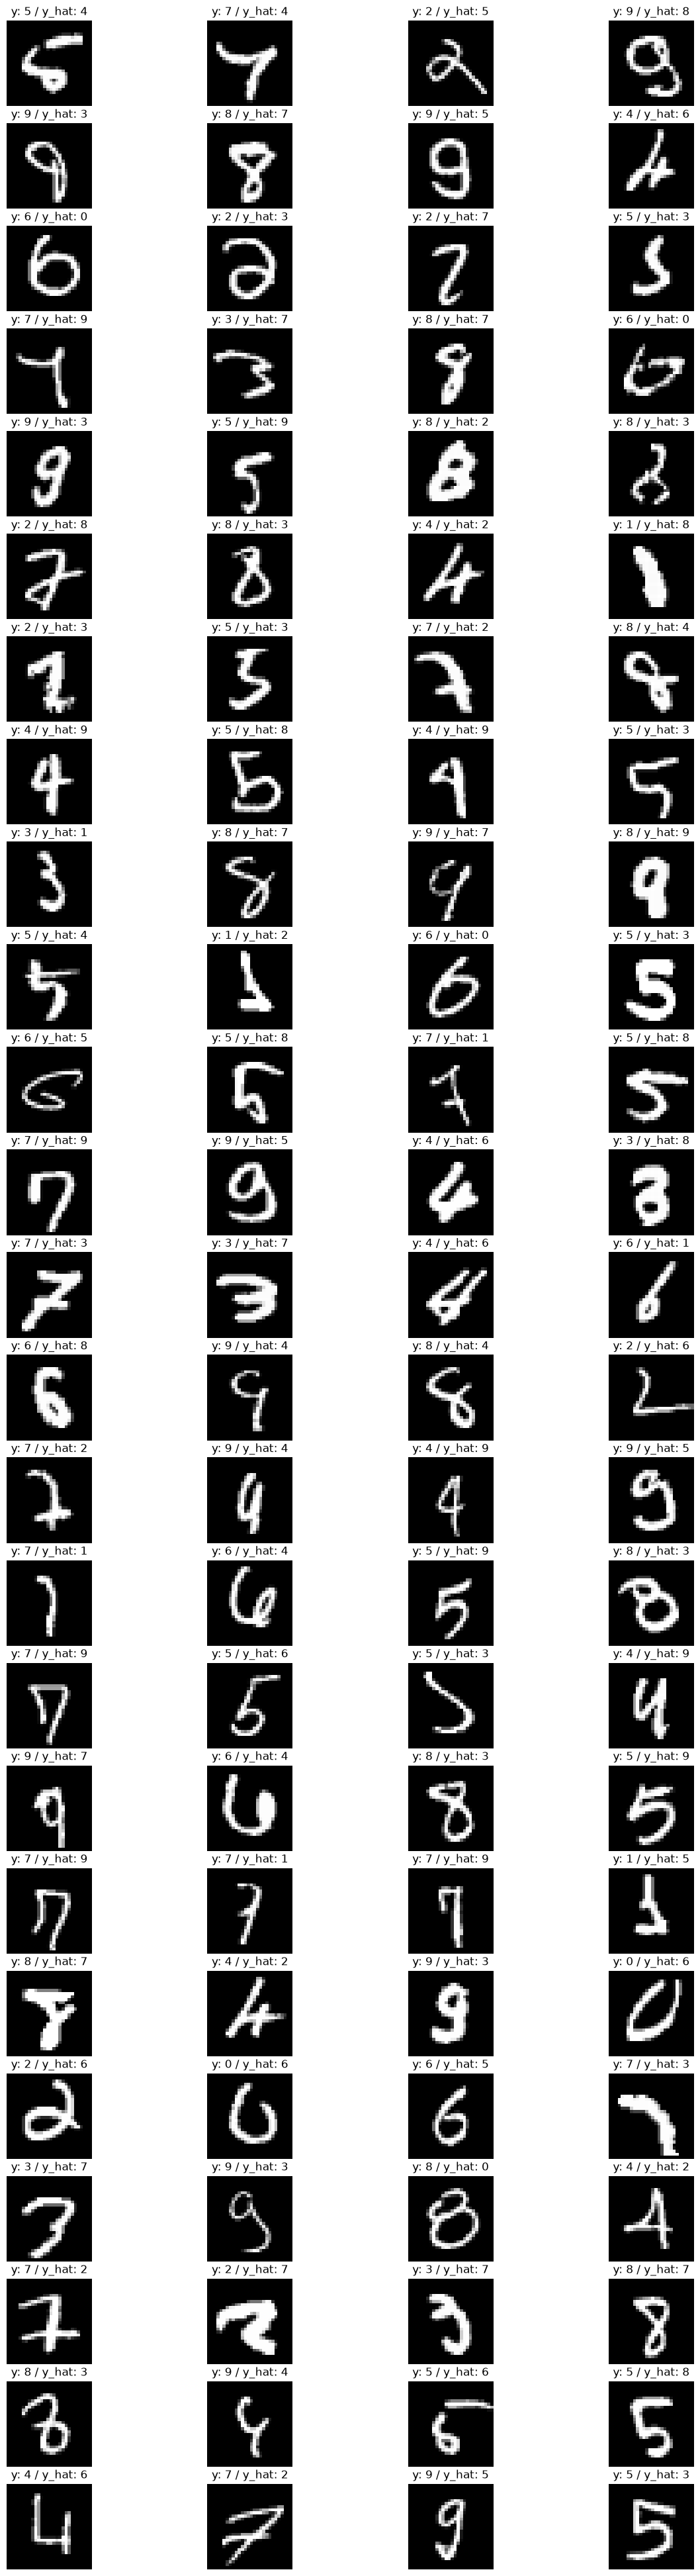

In [30]:
fig = plt.figure(figsize=(15, 50))
z = 0
incorrect_list = []
for i in range(len(test_y)):
    y = test_y[i]
    y_hat = pred_test[i]
    if y != y_hat:
        incorrect_list.append(i)
        if z < 100:
            z += 1
            ax = fig.add_subplot(25, 4, z)
            ax.imshow(test_X[i], cmap=plt.get_cmap('gray'))
            ax.set_title('y: {y} / y_hat: {y_hat}'.format(y=test_y[i], y_hat=pred_test[i]))
            ax.axis('off')
print(len(incorrect_list), "wrong predictions out of", len(test_y))

# Define function for getting derivative of loss with respect to input for saliency maps

In [31]:
def get_saliency_map(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2
    p = np.zeros((1,m))
    
    probas, caches = L_model_forward(X, parameters)
    cost = compute_cost(probas, y)
    grads = L_model_backward(probas, y, caches)
    dy_dx = grads["dA0"]

    return np.argmax(probas, axis=0), dy_dx

# Prepare incorrectly predicted data for saliency maps 

In [32]:
saliency_test = test_x[:, incorrect_list]
saliency_test.reshape(saliency_test.shape[0],len(incorrect_list))
print(saliency_test.shape)

saliency_test_y = test_y[incorrect_list]
print(saliency_test_y.shape)

test_y_one_hot_for_saliency = to_categorical(saliency_test_y)
test_y_one_hot_for_saliency = np.einsum('vz->zv', test_y_one_hot_for_saliency)

(784, 386)
(386,)


# Get predictions and derivative of loss with respect to input

In [33]:
probas, dy_dx = get_saliency_map(saliency_test, test_y_one_hot_for_saliency, parameters)

# Reshape and normalize results for plot 

In [34]:
dy_dx_one_rs = dy_dx.reshape(28,28,dy_dx.shape[1])

normalized_tensor = np.multiply(
    255, (((dy_dx_one_rs - np.min(dy_dx_one_rs))
    / (np.max(dy_dx_one_rs) - np.min(dy_dx_one_rs)))))

# Apply penalty for smaller values

In [35]:
log = (1/(1+np.log((np.max(normalized_tensor) - normalized_tensor + 0.0001))))
normalized_tensor_weighted = np.multiply(normalized_tensor,log)

# The brightest points show the highest impact on loss

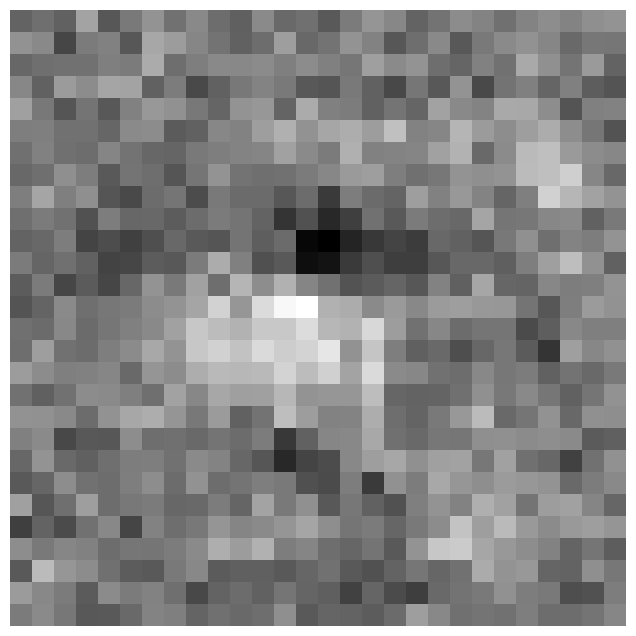

In [36]:
plt.figure(figsize=(8, 8))
plt.axis('off')
plt.imshow(normalized_tensor_weighted[:,:,1], cmap='gray')
plt.show()

# Darken the prediction images so saliency points become the brightest ones in image

In [37]:
saliency_test = test_x[:, incorrect_list]
saliency_test.reshape(saliency_test.shape[0],len(incorrect_list))
saliency_test = saliency_test.reshape(28,28,saliency_test.shape[1])
saliency_test = np.multiply(
    20, (saliency_test - np.min(saliency_test))
    / (np.max(saliency_test) - np.min(saliency_test))
)

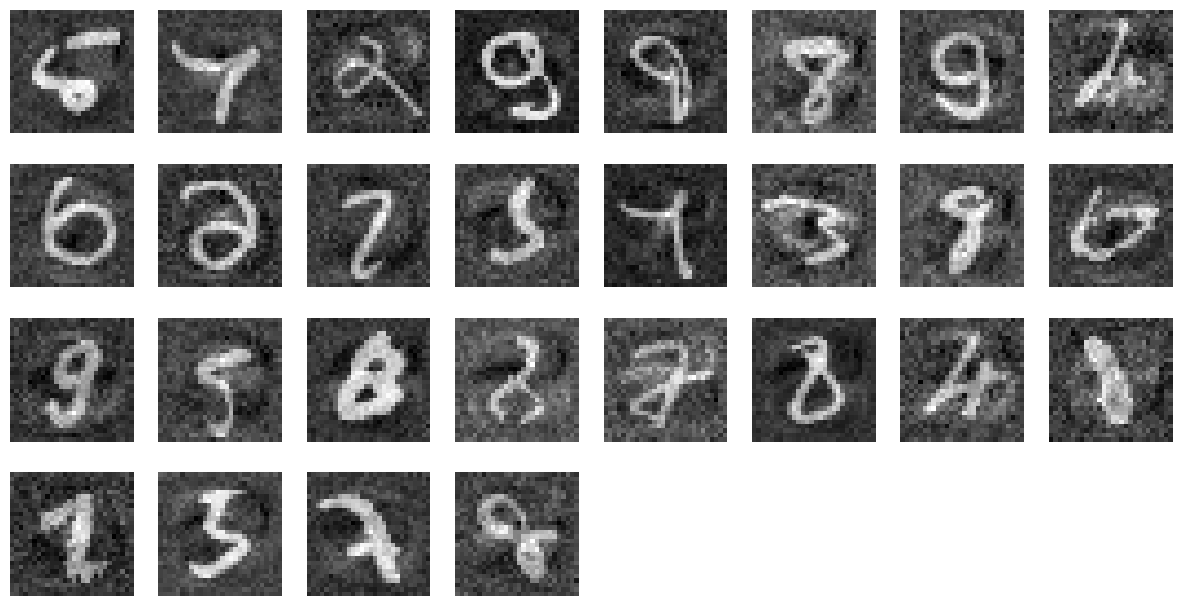

In [38]:
fig = plt.figure(figsize=(15,200))
z = 0
for i in range(saliency_test.shape[1]):
    z += 1
    picture_i = saliency_test[:,:,i]
    saliency_map_i = normalized_tensor_weighted[:,:,i]
    ax = fig.add_subplot(100, 8, z)
    super_imposed = cv2.addWeighted(picture_i, 0.5, saliency_map_i, 0.5, 0.0, dtype=cv2.CV_64F)
    ax.imshow(super_imposed, cmap=plt.get_cmap('gray'))
    
    plt.axis('off')

# Conclusion

**Number of iterations:** I trained the network for 2500 iterations with a learning rate of 0.1. The cost went down smoothly from 0.23 to about 0.0096 and never jumped back up. It was still falling slowly at the end, so more iterations could add a little accuracy, but 2500 was enough for a good result.

**Why my first run only got about 34% accuracy:** In the first run I used a learning rate of 0.9, which was too high. The cost dropped nicely until around iteration 1400 (to about 0.014), then suddenly jumped to about 0.2 and never recovered, even after 5000 iterations. The steps were too big, the weights blew up and many ReLU neurons died. The confusion matrix shows this. Digits 2, 3, 5, 6 and 8 were mostly predicted as 0, and 9 was mostly predicted as 4. Train and test accuracy were almost the same (34.8% and 34.9%) because the model was broken, not because it overfitted.

**Result after lowering the learning rate to 0.1:** Train accuracy is 97.3% and test accuracy is 96.14%. The gap between them is small, so the model is not overfitting much. The only real change from the first run was the learning rate, so that was clearly the cause of the bad accuracy.